# ACE candidate evidence table, zinc-binding annotation and experimental shortlist

This notebook puts the pieces side by side instead of letting a single docking number decide:

- **ML evidence** from notebook 8 (calibrated probability, conformal set, pChEMBL interval, applicability domain),
- **drugability** flags from notebook 3,
- **zinc-binding-group (ZBG) annotation** (carboxylic acid, thiol, phosphorus acid, hydroxamic acid, tetrazole; catechol as a weak chelator), shown as interpretable evidence and **never used as a filter**,
- **docking** results, only if present, labelled with their validation status and with the result of the docking screening-power test (notebook 7).

Candidates are then sorted into **evidence tiers by explicit rules** and a **diverse, controlled shortlist** for an ACE inhibition assay is proposed. Tiers describe computational support, not activity.

In [6]:
from pathlib import Path
import os, sys, json, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/ACE_Workflow')
except ImportError:
    ROOT = Path(os.environ.get('ACE_WORKFLOW_ROOT', Path.cwd())).resolve()
if not (ROOT / 'ace_config.py').exists():
    ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'ace_config.py').exists()), ROOT)
if not (ROOT / 'ace_config.py').exists():
    raise FileNotFoundError('Could not find ace_config.py. Mount Drive or set ACE_WORKFLOW_ROOT.')
os.environ['ACE_WORKFLOW_ROOT'] = str(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import ace_config

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import fisher_exact
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator
from rdkit.SimDivFilters.rdSimDivPickers import MaxMinPicker
RDLogger.DisableLog('rdApp.*')

PATHS = ace_config.PATHS; RANDOM_STATE = ace_config.RANDOM_STATE
EVID = PATHS['ML_RESULTS'] / 'evidence'; DRUG = PATHS['DRUGABILITY']; PROCESSED = PATHS['DATA_PROCESSED']; DOCK = PATHS['DOCKING_REPORTS']
OUT = PATHS['VIS_REPORTS']; OUT.mkdir(parents=True, exist_ok=True); FIG = PATHS['VIS_FIGURES']; Path(FIG).mkdir(parents=True, exist_ok=True)

# Evidence-tier rules (decided before looking at the candidates; edit only with a documented reason)
TIER_A_MIN_P = 0.50      # calibrated probability of activity
TIER_B_MIN_P = 0.30
EXPLORATORY_MIN_P_RAW = 0.50
SHORTLIST_QUOTA = {'A': 12, 'B': 4, 'exploratory': 4}
N_NEGATIVE_CONTROLS = 3
POSITIVE_CONTROLS = {'captopril': 'C[C@@H](CS)C(=O)N1CCC[C@H]1C(=O)O', 'lisinopril': 'NCCCC[C@H](N[C@@H](CCc1ccccc1)C(=O)O)C(=O)N1CCC[C@H]1C(=O)O'}
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def heavy_atoms(smi): return Chem.MolFromSmiles(smi).GetNumHeavyAtoms()
def pick_diverse(df, n):
    """MaxMin diversity pick of n rows (deterministic)."""
    if len(df) <= n: return df
    fps = [fp_gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in df.canonical_smiles]
    idx = MaxMinPicker().LazyBitVectorPick(fps, len(fps), n, seed=RANDOM_STATE)
    return df.iloc[list(idx)]


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# 1. Does the ZBG annotation make sense on YOUR data? Prevalence among measured actives vs measured inactives (ChEMBL training set)
train = pd.read_csv(PROCESSED / 'chembl1808_ic50_clean.csv')
tz = ace_config.annotate_zbg(train)
act = tz[(tz.ic50_nM <= ace_config.IC50_CUTOFF_NM) & ~tz.ic50_censored.astype(bool)]
ina = tz[tz.ic50_nM >= ace_config.CENSORED_INACTIVE_MIN_NM]
rows = []
classes = list(ace_config.ZBG_SMARTS) + list(ace_config.ZBG_WEAK_SMARTS)
for c in ['any strong ZBG'] + classes:
    f = (lambda d: d.has_zbg) if c == 'any strong ZBG' else (lambda d, c=c: d.zbg_classes.str.contains(c) | d.weak_chelator_classes.str.contains(c))
    a, i = int(f(act).sum()), int(f(ina).sum())
    odds, p = fisher_exact([[a, len(act) - a], [i, len(ina) - i]]) if len(act) and len(ina) else (np.nan, np.nan)
    rows.append({'group': c, 'actives_with': a, 'actives_n': len(act), 'frac_actives': a / max(len(act), 1), 'inactives_with': i, 'inactives_n': len(ina), 'frac_inactives': i / max(len(ina), 1), 'odds_ratio': odds, 'fisher_p': p})
zbg_check = pd.DataFrame(rows); display(zbg_check.round(3))
zbg_check.to_csv(OUT / 'zbg_annotation_check_chembl.csv', index=False)
print(f'{act.has_zbg.mean():.0%} of the {len(act)} measured actives and {ina.has_zbg.mean():.0%} of the {len(ina)} measured inactives carry a strong ZBG.')


,group,actives_with,actives_n,frac_actives,inactives_with,inactives_n,frac_inactives,odds_ratio,fisher_p
0,any strong ZBG,143,156,0.917,146,195,0.749,3.692,0.000
1,carboxylic_acid,141,156,0.904,129,195,0.662,4.809,0.000
2,thiol,58,156,0.372,28,195,0.144,3.530,0.000
3,phosphorus_acid,5,156,0.032,2,195,0.010,3.195,0.249
4,hydroxamic_acid,1,156,0.006,11,195,0.056,0.108,0.015
5,tetrazole,1,156,0.006,1,195,0.005,1.252,1.000
6,catechol,1,156,0.006,10,195,0.051,0.119,0.026


92% of the 156 measured actives and 75% of the 195 measured inactives carry a strong ZBG.


In [8]:
# 2. Merge ML evidence, drugability, ZBG and (optional) docking
ev = pd.read_csv(EVID / 'ml_evidence_candidates.csv')
dr = pd.read_csv(DRUG / 'ace_drugability_all_candidates.csv')
cols = [c for c in ['source', 'canonical_smiles', 'drugability_pass', 'model_pass', 'admet_descriptor_pass', 'glaxo_alert_pass', 'glaxo_alert_count', 'glaxo_alerts', 'mw', 'logp', 'tpsa', 'hbd', 'hba', 'rotatable_bonds', 'priority_score'] if c in dr.columns]
tab = ev.merge(dr[cols], on=['source', 'canonical_smiles'], how='left', validate='one_to_one')
tab['drugability_pass'] = tab.drugability_pass.fillna(False).astype(bool)
tab = ace_config.annotate_zbg(tab)

# docking: reported with its validation status; counted as supporting evidence only if the screening-power test (notebook 7) was run
# with the SAME docking protocol and shows that the score separates actives from inactives beyond ligand size
ens_file, flex_file, power_file = DOCK / 'ensemble_docking_results.csv', DOCK / 'ace_1o86_integrated_docking.csv', DOCK / 'docking_screening_power_summary.json'
ENS_NAME = 'conformer_ensemble_rigid_docking_then_flexible_refinement'
dk, dock_protocol = None, None
if ens_file.exists():
    dk, dock_protocol = pd.read_csv(ens_file), ENS_NAME
    if 'role' in dk.columns: dk = dk[~dk.role.astype(str).str.contains('control')]
elif flex_file.exists():
    dk, dock_protocol = pd.read_csv(flex_file), 'flexible_vina'
    if 'is_control' in dk.columns: dk = dk[dk.is_control != True]
    dk = dk.rename(columns={'best_affinity_kcal_mol': 'dock_score_kcal', 'mean_affinity_kcal_mol': 'dock_mean_score_kcal', 'n_seeds_done': 'dock_n_seeds', 'redocking_validation': 'docking_validation'})
docking_available = dk is not None
power = json.loads(power_file.read_text()) if power_file.exists() else None
verdict = power['verdict'] if power else 'NOT_ASSESSED'
power_protocol = (power.get('protocol') or {}).get('name') if power else None
effective = 'PROTOCOL_MISMATCH' if (power and docking_available and power_protocol != dock_protocol) else verdict
DOCKING_USE = {'USEFUL_BEYOND_SIZE': 'supporting (screening power demonstrated beyond ligand size)',
               'SEPARATES_NOT_BEYOND_SIZE': 'reported only (separates actives but not demonstrably beyond ligand size)',
               'NO_EVIDENCE': 'reported only (no evidence the score separates actives from inactives)',
               'NOT_ASSESSED': 'reported only (screening power not assessed)',
               'PROTOCOL_MISMATCH': f'reported only (the screening-power test used a different docking protocol: {power_protocol})'}[effective]
if docking_available:
    dcols = [c for c in ['canonical_smiles', 'dock_score_kcal', 'dock_mean_score_kcal', 'dock_n_seeds', 'dg_vs_lisinopril_kcal', 'dg_acceptable', 'docking_validation'] if c in dk.columns]
    tab = tab.merge(dk[dcols].drop_duplicates('canonical_smiles'), on='canonical_smiles', how='left')
    print('Docking protocol:', dock_protocol); print('Docking use     :', DOCKING_USE); print('Validation      :', dk.docking_validation.iloc[0] if 'docking_validation' in dk.columns and len(dk) else 'unknown')
else:
    print('No docking results found; docking columns omitted.')
dock_supports = (effective == 'USEFUL_BEYOND_SIZE')

# 3. Evidence signals and tiers
tab['sig_conformal_active'] = tab.conformal_set.eq('active')
tab['sig_interval_clears_cutoff'] = tab.reg_interval_clears_cutoff.astype(bool)
tab['sig_zbg'] = tab.has_zbg
tab['sig_docking'] = (tab.get('dg_acceptable', pd.Series(False, index=tab.index)).fillna(False).astype(bool) & dock_supports) if docking_available else False
tab['n_supporting_signals'] = tab[['sig_conformal_active', 'sig_interval_clears_cutoff', 'sig_zbg', 'sig_docking']].sum(axis=1)
in_dom, bord, ood = tab.ad_level.eq('in-domain'), tab.ad_level.eq('borderline'), tab.ad_level.eq('out-of-domain')
A = tab.drugability_pass & tab.conformal_set.eq('active') & (tab.p_active_cal >= TIER_A_MIN_P) & in_dom
B = tab.drugability_pass & tab.conformal_set.isin(['active', 'uncertain (both)']) & (tab.p_active_cal >= TIER_B_MIN_P) & (in_dom | bord) & ~A
X = tab.drugability_pass & (tab.p_active_raw >= EXPLORATORY_MIN_P_RAW) & ood
tab['evidence_tier'] = np.select([A, B, X], ['A', 'B', 'exploratory'], default='unsupported')
print(tab.evidence_tier.value_counts().to_string())
tab.to_csv(OUT / 'candidate_evidence_table_all_rows.csv', index=False)

# one row per chemical (same structure can appear in several libraries)
tab = tab.sort_values(['p_active_raw'], ascending=False)
agg = {'source': lambda s: ' | '.join(sorted(set(map(str, s))))}
if 'source_id' in tab.columns: agg['source_id'] = lambda s: ' | '.join(sorted(set(map(str, s)))[:5])
uniq = tab.groupby('canonical_smiles', as_index=False, sort=False).agg({**agg, **{c: 'first' for c in tab.columns if c not in ('canonical_smiles', 'source', 'source_id')}})
uniq = uniq.sort_values(['evidence_tier', 'p_active_raw'], key=lambda s: s.map({'A': 0, 'B': 1, 'exploratory': 2, 'unsupported': 3}) if s.name == 'evidence_tier' else -s)
uniq.to_csv(OUT / 'candidate_evidence_table.csv', index=False)
print(f'{len(uniq):,} unique chemicals;', uniq.evidence_tier.value_counts().to_dict())


Docking protocol: conformer_ensemble_rigid_docking_then_flexible_refinement
Docking use     : reported only (screening power not assessed)
Validation      : WEAKLY VALIDATED for pose reproduction of lisinopril: top-ranked pose within 2 A in 2/3 redocking seeds, median score margin 0.35 kcal/mol; affinity ranking not validated here


/tmp/ipykernel_2815/2898612095.py:43: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  tab['sig_docking'] = (tab.get('dg_acceptable', pd.Series(False, index=tab.index)).fillna(False).astype(bool) & dock_supports) if docking_available else False


evidence_tier
unsupported    159657
A                   1
96,174 unique chemicals; {'unsupported': 96173, 'A': 1}


In [9]:
# 4. Experimental shortlist: diverse picks per tier + controls
picked = []
for tier, quota in SHORTLIST_QUOTA.items():
    pool = uniq[uniq.evidence_tier == tier].sort_values(['p_active_raw', 'n_supporting_signals'], ascending=False).head(max(5 * quota, 50))
    chosen = pick_diverse(pool, quota); picked.append(chosen.assign(role=f'candidate (tier {tier})'))
    if len(chosen) < quota: print(f'Tier {tier}: only {len(chosen)} of {quota} requested candidates available.')
short = pd.concat(picked, ignore_index=True) if picked else pd.DataFrame()

def rationale(r):
    bits = [f"p_cal {r.p_active_cal:.2f}", f"set {r.conformal_set}", f"pChEMBL {r.pchembl_lo:.1f}-{r.pchembl_hi:.1f} (IC50 {r.ic50_lo_nM:.0f}-{r.ic50_hi_nM:.0f} nM)", f"AD {r.ad_level} (sim {min(r.max_train_tanimoto_cls, r.max_train_tanimoto_reg):.2f})",
            f"ZBG {r.zbg_classes or 'none'}" + (f" (weak: {r.weak_chelator_classes})" if r.weak_chelator_classes else ''), 'drugability pass' if r.drugability_pass else 'drugability FAIL']
    if docking_available and 'dock_score_kcal' in r.index and pd.notna(r.dock_score_kcal): bits.append(f"Vina {r.dock_score_kcal:.1f} kcal/mol [{DOCKING_USE.split(' (')[0]}]")
    return '; '.join(bits)
if len(short): short['rationale'] = short.apply(rationale, axis=1)

pos = pd.DataFrame([{'canonical_smiles': s, 'role': 'positive control (known ACE inhibitor)', 'source_id': k, 'rationale': 'established ACE inhibitor; verifies the assay'} for k, s in POSITIVE_CONTROLS.items()])
med_ha = float(np.median([heavy_atoms(s) for s in short.canonical_smiles])) if len(short) else 25.0
neg_pool = train[(train.ic50_nM >= ace_config.CENSORED_INACTIVE_MIN_NM) & ~train.ic50_censored.astype(bool)]
if len(neg_pool) < N_NEGATIVE_CONTROLS: neg_pool = train[train.ic50_nM >= ace_config.CENSORED_INACTIVE_MIN_NM]
neg_pool = neg_pool.assign(ha_gap=[abs(heavy_atoms(s) - med_ha) for s in neg_pool.canonical_smiles]).sort_values('ha_gap').head(30)
neg = pick_diverse(neg_pool, N_NEGATIVE_CONTROLS)[['canonical_smiles', 'ic50_nM']].assign(role='negative control (ChEMBL-reported inactive, biochemical)')
neg['rationale'] = neg.ic50_nM.map(lambda v: f'ChEMBL IC50 >= {v:.0f} nM; size-matched to the shortlist; check commercial availability')
plan = pd.concat([short, pos, neg.drop(columns='ic50_nM')], ignore_index=True)
front = [c for c in ['role', 'canonical_smiles', 'source', 'source_id', 'evidence_tier', 'rationale'] if c in plan.columns]
plan = plan[front + [c for c in plan.columns if c not in front]]
plan.to_csv(OUT / 'experiment_plan.csv', index=False)
print(f'Experiment plan: {len(short)} candidates + {len(pos)} positive + {len(neg)} negative controls'); display(plan[front].head(30))


Tier A: only 1 of 12 requested candidates available.
Tier B: only 0 of 4 requested candidates available.
Tier exploratory: only 0 of 4 requested candidates available.
Experiment plan: 1 candidates + 2 positive + 3 negative controls


,role,canonical_smiles,source,source_id,evidence_tier,rationale
0,candidate (tier A),CC(NC(CCc1ccccc1)C(=O)O)C(=O)N1CCCC1C(=O)O,FDA_DRUGBANK,Enalaprilat,A,p_cal 0.94; set active; pChEMBL 7.3-9.5 (IC50 ...
1,positive control (known ACE inhibitor),C[C@@H](CS)C(=O)N1CCC[C@H]1C(=O)O,NaN,captopril,NaN,established ACE inhibitor; verifies the assay
2,positive control (known ACE inhibitor),NCCCC[C@H](N[C@@H](CCc1ccccc1)C(=O)O)C(=O)N1CC...,NaN,lisinopril,NaN,established ACE inhibitor; verifies the assay
3,"negative control (ChEMBL-reported inactive, bi...",NC(N)=NCCC[C@H](N)C(=O)N[C@@H](Cc1ccccc1)C(=O)O,NaN,NaN,NaN,ChEMBL IC50 >= 229087 nM; size-matched to the ...
4,"negative control (ChEMBL-reported inactive, bi...",O=c1oc2c(O)c(O)cc3c(=O)oc4c(O)c(O)cc1c4c23,NaN,NaN,NaN,ChEMBL IC50 >= 5000000 nM; size-matched to the...
5,"negative control (ChEMBL-reported inactive, bi...",CCCc1cnc(N2C[C@H](S)CC2CNCc2cc(F)ccc2F)nc1,NaN,NaN,NaN,ChEMBL IC50 >= 31623 nM; size-matched to the s...


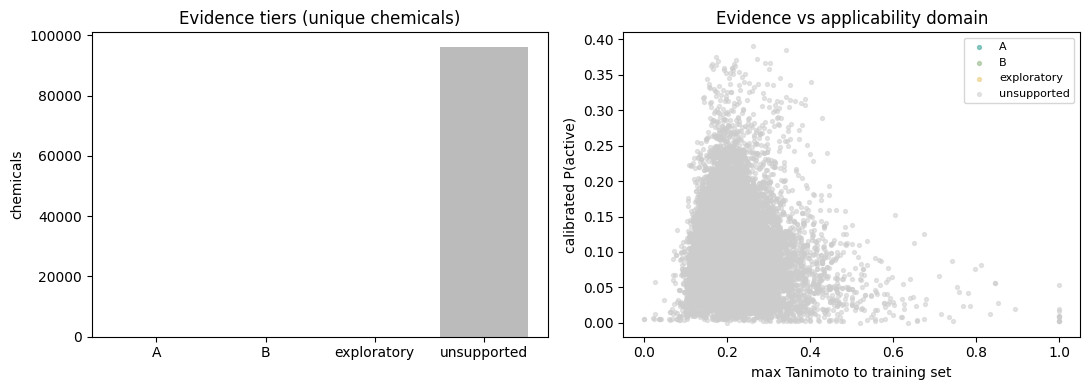

{
  "unique_chemicals": 96174,
  "tier_counts": {
    "unsupported": 96173,
    "A": 1
  },
  "shortlist_candidates": 1,
  "positive_controls": 2,
  "negative_controls": 3,
  "docking_available": true,
  "docking_protocol": "conformer_ensemble_rigid_docking_then_flexible_refinement",
  "docking_use": "reported only (screening power not assessed)",
  "docking_screening_power_verdict": "NOT_ASSESSED",
  "screening_power_protocol": null,
  "tier_rules": {
    "A": "drugability pass, conformal set active, calibrated p >= 0.5, in-domain",
    "B": "drugability pass, conformal active/uncertain, calibrated p >= 0.3, in-domain or borderline",
    "exploratory": "drugability pass, raw p >= 0.5, out-of-domain (reliability unknown)"
  },
  "zbg_is_a_filter": false
}


In [10]:
# 5. Figures and summary
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ['A', 'B', 'exploratory', 'unsupported']; counts = uniq.evidence_tier.value_counts().reindex(order).fillna(0)
ax[0].bar(order, counts.values, color=['#2a9d8f', '#8ab17d', '#e9c46a', '#bbbbbb']); ax[0].set_title('Evidence tiers (unique chemicals)'); ax[0].set_ylabel('chemicals')
s = uniq.sample(min(15000, len(uniq)), random_state=RANDOM_STATE)
for t, c in zip(order, ['#2a9d8f', '#8ab17d', '#e9c46a', '#cccccc']):
    d = s[s.evidence_tier == t]; ax[1].scatter(d.max_train_tanimoto_cls, d.p_active_cal, s=8, alpha=.5, color=c, label=t)
ax[1].set_xlabel('max Tanimoto to training set'); ax[1].set_ylabel('calibrated P(active)'); ax[1].legend(fontsize=8); ax[1].set_title('Evidence vs applicability domain')
fig.tight_layout(); fig.savefig(Path(FIG) / 'evidence_tiers.png', dpi=200); plt.show()
summary = {'unique_chemicals': int(len(uniq)), 'tier_counts': uniq.evidence_tier.value_counts().to_dict(), 'shortlist_candidates': int(len(short)), 'positive_controls': int(len(pos)), 'negative_controls': int(len(neg)),
           'docking_available': bool(docking_available), 'docking_protocol': dock_protocol, 'docking_use': DOCKING_USE, 'docking_screening_power_verdict': verdict, 'screening_power_protocol': power_protocol,
           'tier_rules': {'A': f'drugability pass, conformal set active, calibrated p >= {TIER_A_MIN_P}, in-domain', 'B': f'drugability pass, conformal active/uncertain, calibrated p >= {TIER_B_MIN_P}, in-domain or borderline',
                          'exploratory': f'drugability pass, raw p >= {EXPLORATORY_MIN_P_RAW}, out-of-domain (reliability unknown)'}, 'zbg_is_a_filter': False}
(OUT / 'evidence_summary.json').write_text(json.dumps(summary, indent=2, default=float)); print(json.dumps(summary, indent=2, default=float))


### Reading the results

- **Tier A:** drugability pass, a confident `active` conformal call, calibrated probability above the threshold and an in-domain structure: the strongest *computational* support.
- **Tier B:** weaker or less certain support within or near the training chemistry.
- **Exploratory:** high raw score but out-of-domain: the models' reliability is unknown there, so these are hypothesis-generating (and worth including in the assay precisely to test extrapolation).
- **Docking** is shown but only counted as a supporting signal if notebook 7 demonstrates that the score separates actives from inactives beyond ligand size; otherwise it is reported for transparency only.
- **ZBG** flags explain *why* a compound might plausibly inhibit ACE; they are not required (some natural-product inhibitors may act differently) and are never used to exclude compounds.
- The shortlist deliberately mixes tiers and includes positive and negative controls so the assay also tests the models. Experimental ACE inhibition remains the confirmation.